In [ ]:
import xarray as xr
import pygrib
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.signal import butter, filtfilt
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from scipy.integrate import solve_ivp

In [ ]:
def get_h_month(grb_file):

    grbs = pygrib.open(grb_file)

    temp_list = []
    depth_list = []

    for g in grbs:
        if "Potential temperature" in g.name or "POT" in g.name:
            temp_list.append(g.values)
            depth_list.append(g.level)

    temp = np.array(temp_list)
    depth = np.array(depth_list)

    temp[temp > 1000] = np.nan

    temp = temp - 273.15

    lats, lons = g.latlons()

    if temp.ndim != 3:
        raise ValueError("No vertical levels found → cannot compute D20")

    mask = (temp[:-1] - 20) * (temp[1:] - 20) <= 0
    valid = mask.any(axis=0)

    k = np.argmax(mask, axis=0)

    nz, ny, nx = temp.shape
    D20 = np.full((ny, nx), np.nan)

    j, i = np.where(valid)
    kk = k[j, i]

    T1 = temp[kk, j, i]
    T2 = temp[kk + 1, j, i]

    z1 = depth[kk]
    z2 = depth[kk + 1]

    D20[j, i] = z1 + (20 - T1) * (z2 - z1) / (T2 - T1)

    lat = lats[:,0]
    lon = lons[0,:]

    lat_mask = (lat >= -5) & (lat <= 5)
    lon_mask = (lon >= 120) & (lon <= 280)

    return np.nanmean(D20[np.ix_(lat_mask, lon_mask)])

In [3]:
get_h_month("E:\data\godas.M.198010.grb")

132.53001250621088

In [4]:
def get_sst_month(grb_file):

    import numpy as np, pygrib

    grbs = pygrib.open(grb_file)

    sst_list = []

    for g in grbs:
        if "Potential temperature" in g.name or "POT" in g.name:
            sst_list.append(g.values)

    sst = np.array(sst_list)

    sst = np.where(sst > 1000, np.nan, sst)
    sst = sst - 273.15 

    grbs.rewind()
    g0 = next(grbs)
    lats, lons = g0.latlons()

    lat = lats[:, 0]
    lon = lons[0, :]

    lat_mask = (lat >= -5) & (lat <= 5)
    lon_mask = (lon >= 210) & (lon <= 280)   

    return np.nanmean(sst[0][np.ix_(lat_mask, lon_mask)])

In [5]:
get_sst_month("E:\data\godas.M.198010.grb")

24.32056279961652

In [6]:
h_series = []
sst_series = []
time_index = []

for year in range(1980, 2026):
    for month in range(1, 13):

        file_name = f"E:/data/godas.M.{year}{month:02d}.grb"
        time_index.append(f"{year}-{month:02d}")

        if not os.path.exists(file_name):
            print(f"[MISSING FILE] {file_name}")
            h_series.append(np.nan)
            sst_series.append(np.nan)
            continue

        try:
            h = get_h_month(file_name)
            sst = get_sst_month(file_name)
            h_series.append(h)
            sst_series.append(sst)

        except Exception as e:
            print(f"[ERROR] {file_name}: {e}")
            h_series.append(np.nan)
            sst_series.append(np.nan)

h_series = np.array(h_series)
sst_series = np.array(sst_series)

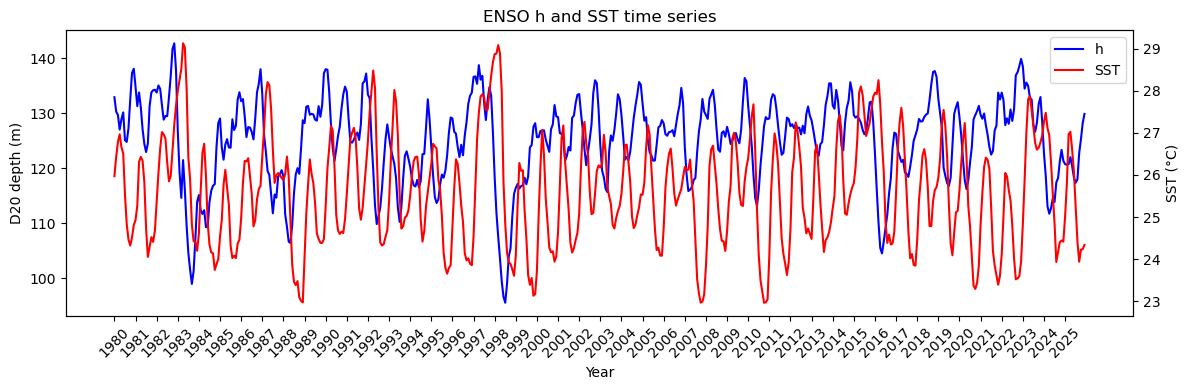

In [140]:
year_ticks = np.arange(0, len(h_series), 12)
year_labels = [time_index[i][:4] for i in year_ticks]

fig, ax1 = plt.subplots(figsize=(12, 4))

line1 = ax1.plot(h_series, label='h', color='b')
ax1.set_ylabel('D20 depth (m)')

ax2 = ax1.twinx()
line2 = ax2.plot(sst_series, label='SST', color='r')
ax2.set_ylabel('SST (°C)')

ax1.set_xticks(year_ticks)
ax1.set_xticklabels(year_labels, rotation=45)
ax1.set_xlabel('Year')

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.title('ENSO h and SST time series')
plt.tight_layout()
plt.show()

In [ ]:
T_cut = 3
fs = 1.0

fc = 1 / T_cut
fn = fs / 2

Wn = fc / fn

b, a = butter(4, Wn, btype='low')

h_filt = filtfilt(b, a, h_series)
sst_filt = filtfilt(b, a, sst_series)

h = (h_filt - np.mean(h_filt))/np.std(h_filt)
T = (sst_filt - np.mean(sst_filt))/np.std(sst_filt)

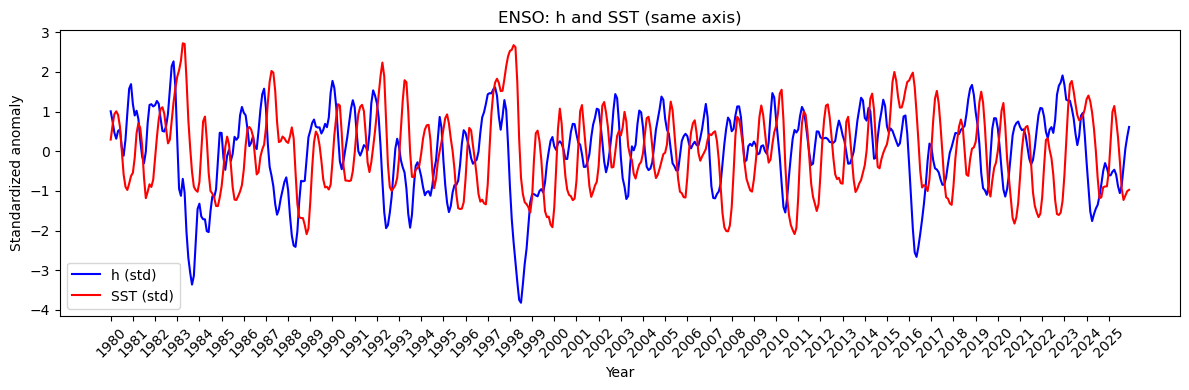

In [141]:
plt.figure(figsize=(12,4))

plt.plot(h, label='h (std)', color='b')
plt.plot(T, label='SST (std)', color='r')

plt.xticks(year_ticks, year_labels, rotation=45)
plt.xlabel("Year")
plt.ylabel("Standardized anomaly")
plt.title("ENSO: h and SST (same axis)")

plt.legend()
plt.tight_layout()
plt.show()

In [89]:
scaler_x = StandardScaler()
X = np.column_stack([h, T])
X = scaler_x.fit_transform(X)

dt = 1

h = X[:, 0]
T = X[:, 1]

dhdt = np.gradient(h, dt)
dTdt = np.gradient(T, dt)

Xdot = np.column_stack([dhdt, dTdt])

In [90]:
Theta = np.column_stack([h,T,h**2,T**2,h**3,T**3,h*T, h**2*T, h*T**2])
feature_names = ["h", "T", "h^2", "T^2", "h^3", "T^3", "hT", "Th^2","hT^2"]

# Theta = np.column_stack([h,T,h**2,T**2,h**3,T**3])
# feature_names = ["h", "T", "h^2", "T^2", "h^3", "T^3"]

model_h = Lasso(alpha=1e-3, fit_intercept=False, max_iter=10000)
model_T = Lasso(alpha=1e-3, fit_intercept=False, max_iter=10000)

model_h.fit(Theta, Xdot[:, 0])
model_T.fit(Theta, Xdot[:, 1])

print("\n===== dh/dt equation =====")
for coef, name in zip(model_h.coef_, feature_names):
    print(f"{coef: .4f} * {name}")

print("\n===== dT/dt equation =====")
for coef, name in zip(model_T.coef_, feature_names):
    print(f"{coef: .4f} * {name}")


===== dh/dt equation =====
-0.0257 * h
-0.2447 * T
 0.0159 * h^2
-0.0138 * T^2
 0.0074 * h^3
 0.0124 * T^3
 0.0573 * hT
 0.0032 * Th^2
-0.0101 * hT^2

===== dT/dt equation =====
 0.2594 * h
 0.0329 * T
 0.0022 * h^2
 0.0060 * T^2
-0.0000 * h^3
-0.0000 * T^3
 0.0121 * hT
-0.0279 * Th^2
-0.0425 * hT^2


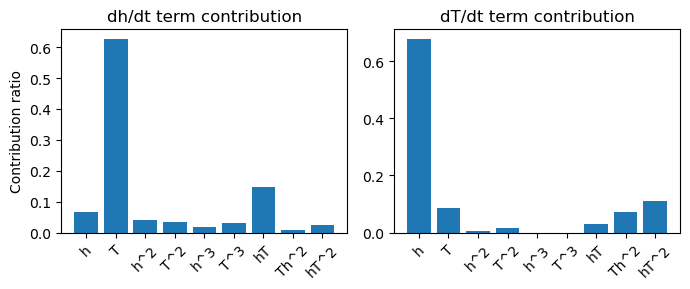

In [138]:
coef_h = model_h.coef_
coef_T = model_T.coef_

abs_coef_h = np.abs(coef_h)
share_h = abs_coef_h / (np.sum(abs_coef_h) + 1e-12)

abs_coef_T = np.abs(coef_T)
share_T = abs_coef_T / (np.sum(abs_coef_T) + 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))

axes[0].bar(feature_names, share_h)
axes[0].set_title("dh/dt term contribution")
axes[0].set_ylabel("Contribution ratio")
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(feature_names, share_T)
axes[1].set_title("dT/dt term contribution")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [111]:
def rhs(t, X):
    h, T = X

    Theta_reconstruct = np.array([h,T,h**2,T**2,h**3,T**3,h*T,h**2*T,T*h**2])
    # Theta_reconstruct = np.array([h,T,h**2,T**2,h**3,T**3])

    dhdt = float(np.dot(model_h.coef_, Theta_reconstruct))
    dTdt = float(np.dot(model_T.coef_, Theta_reconstruct))

    return [dhdt, dTdt]

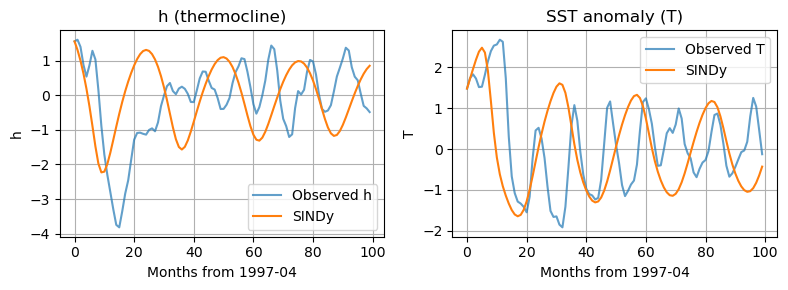

In [125]:
t0 = "1997-04"
idx0 = np.where(np.array(time_index) == t0)[0][0]
X0 = X[idx0]

n_months = 100

h_obs_cut = X[idx0:idx0 + n_months, 0]
T_obs_cut = X[idx0:idx0 + n_months, 1]
t_obs_cut = np.arange(len(h_obs_cut)) * dt

t_span = (0, n_months)
t_eval = np.arange(n_months) * dt

sol = solve_ivp(rhs, t_span, X0, t_eval=t_eval, method="RK45")

h_recon = sol.y[0]
T_recon = sol.y[1]
t_recon = t_eval


fig, axes = plt.subplots(1, 2, figsize=(8, 3))

# -------- h --------
axes[0].plot(t_obs_cut, h_obs_cut, label="Observed h", alpha=0.7)
axes[0].plot(t_recon, h_recon, label="SINDy", linewidth=1.5)
axes[0].set_title("h (thermocline)")
axes[0].set_xlabel("Months from 1997-04")
axes[0].set_ylabel("h")
axes[0].legend()
axes[0].grid(True)

# -------- T --------
axes[1].plot(t_obs_cut, T_obs_cut, label="Observed T", alpha=0.7)
axes[1].plot(t_recon, T_recon, label="SINDy", linewidth=1.5)
axes[1].set_title("SST anomaly (T)")
axes[1].set_xlabel("Months from 1997-04")
axes[1].set_ylabel("T")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

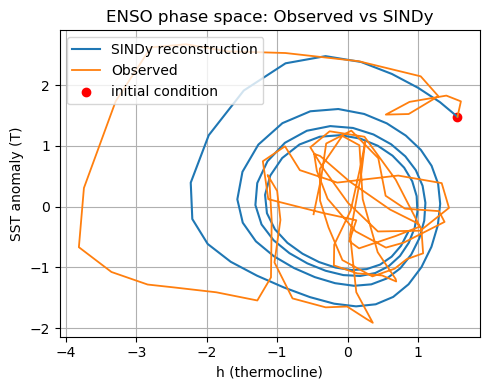

In [135]:
h_traj = sol.y[0]
T_traj = sol.y[1]

h_obs_traj = X[idx0:idx0 + n_months, 0]
T_obs_traj = X[idx0:idx0 + n_months, 1]

plt.figure(figsize=(5,4))


plt.plot(h_traj, T_traj, lw=1.5, label="SINDy reconstruction")
plt.plot(h_obs_traj, T_obs_traj, lw=1.3, label="Observed")

# initial condition
plt.scatter(X0[0], X0[1], color='red', label='initial condition')

plt.xlabel("h (thermocline)")
plt.ylabel("SST anomaly (T)")
plt.title("ENSO phase space: Observed vs SINDy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()